In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "stockwise.db").exists():
    ROOT = ROOT.parent

con = sqlite3.connect(ROOT / "stockwise.db")
sales = pd.read_sql_query("SELECT * FROM sales_enriched", con, parse_dates=["sale_date"])
products = pd.read_sql_query("SELECT * FROM products", con)
inventory = pd.read_sql_query("SELECT * FROM inventory", con)
SNAP = pd.Timestamp("2026-03-31")   
print(sales.shape, products.shape, inventory.shape)

(346107, 19) (120, 9) (720, 6)


In [2]:
fy = sales[sales["fy"] == "2025-26"]
abc = (fy.groupby(["product_id", "sku_name", "category"], as_index=False)["net_revenue"].sum()
         .sort_values("net_revenue", ascending=False).reset_index(drop=True))

abc["pct"] = abc["net_revenue"] / abc["net_revenue"].sum() * 100
abc["cum_pct"] = abc["pct"].cumsum()
start = abc["cum_pct"] - abc["pct"]                      # where each product begins on the curve
abc["abc_class"] = np.where(start < 80, "A", np.where(start < 95, "B", "C"))

summary = abc.groupby("abc_class").agg(skus=("product_id", "count"),
                                       revenue=("net_revenue", "sum"))
summary["pct_of_skus"] = (summary["skus"] / len(abc) * 100).round(1)
summary["pct_of_revenue"] = (summary["revenue"] / summary["revenue"].sum() * 100).round(1)
print(len(abc), "products ranked")
summary

120 products ranked


,skus,revenue,pct_of_skus,pct_of_revenue
abc_class,,,,
A,60,3.166392e+07,50.0,80.5
B,35,5.803798e+06,29.2,14.8
C,25,1.857864e+06,20.8,4.7


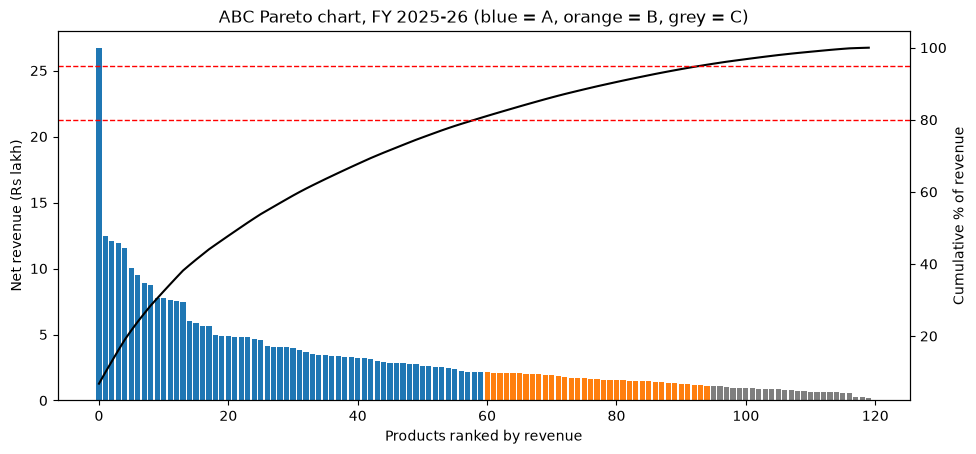

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(range(len(abc)), abc["net_revenue"] / 1e5,
       color=abc["abc_class"].map({"A": "#1f77b4", "B": "#ff7f0e", "C": "#7f7f7f"}))
ax.set_ylabel("Net revenue (Rs lakh)")
ax.set_xlabel("Products ranked by revenue")
ax2 = ax.twinx()
ax2.plot(range(len(abc)), abc["cum_pct"], color="black")
ax2.axhline(80, ls="--", color="red", lw=1)
ax2.axhline(95, ls="--", color="red", lw=1)
ax2.set_ylabel("Cumulative % of revenue")
ax.set_title("ABC Pareto chart, FY 2025-26 (blue = A, orange = B, grey = C)")
fig.savefig(ROOT / "images" / "05_abc_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

abc.to_csv(ROOT / "data" / "abc_analysis.csv", index=False)

In [4]:
last_sale = sales.groupby("product_id")["sale_date"].max().rename("last_sale_date")
units = inventory.groupby("product_id")["stock_on_hand"].sum().rename("units_in_stock")

dead = (products.set_index("product_id")[["sku_name", "category", "unit_cost"]]
        .join(last_sale).join(units))
dead["days_since_last_sale"] = (SNAP - dead["last_sale_date"]).dt.days
dead["stock_value_cost"] = (dead["units_in_stock"] * dead["unit_cost"]).round(0)

dead_stock = (dead[dead["days_since_last_sale"] >= 60]
              .sort_values("stock_value_cost", ascending=False).reset_index())


expected = {"P005", "P009", "P024", "P060", "P069", "P079", "P092", "P097"}
assert set(dead_stock["product_id"]) == expected, "Dead stock list does not match the answer key"

print(f"Dead stock products: {len(dead_stock)}")
print(f"Capital locked at cost: Rs {dead_stock['stock_value_cost'].sum():,.0f}")
dead_stock[["product_id", "sku_name", "category", "last_sale_date",
            "days_since_last_sale", "units_in_stock", "stock_value_cost"]]

Dead stock products: 8
Capital locked at cost: Rs 432,946


,product_id,sku_name,category,last_sale_date,days_since_last_sale,units_in_stock,stock_value_cost
0,P060,Rose Syrup 750 ml,Beverages,2025-12-31,90,1228,113750.0
1,P024,Ghee 500 ml,Dairy,2025-12-31,90,458,110470.0
2,P069,Sunscreen 50 g,Personal Care,2025-12-31,90,471,107638.0
3,P092,Mixed Fruit Jam 500 g,Packaged Foods,2025-12-31,90,252,28032.0
4,P009,Sugar 1 kg,Staples & Grains,2025-12-31,90,629,24531.0
5,P079,Dishwash Bar 3 pack,Household,2025-12-31,90,553,21440.0
6,P097,Oats 1 kg,Packaged Foods,2025-12-31,90,98,15595.0
7,P005,Moong Dal 1 kg,Staples & Grains,2025-12-31,90,96,11490.0


In [5]:
dead_stock.to_csv(ROOT / "data" / "dead_stock.csv", index=False)